In [8]:
!pip -q install gradio optuna kagglehub

In [9]:
import os, time, copy, random, json
from collections import defaultdict, Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import optuna

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)

Device: cuda


In [10]:
import kagglehub
DATA_ROOT = kagglehub.dataset_download("salmansajid05/oral-diseases")
print("Downloaded to:", DATA_ROOT)

# Optional: keep results on Google Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/oral_project_outputs"
except Exception:
    SAVE_DIR = "/content/outputs"
os.makedirs(SAVE_DIR, exist_ok=True)

# Show the folder structure (2 levels) so you can verify it
for dp, dn, fn in os.walk(DATA_ROOT):
    depth = dp[len(DATA_ROOT):].count(os.sep)
    if depth <= 2:
        n_img = sum(f.lower().endswith((".jpg",".jpeg",".png",".bmp",".webp")) for f in fn)
        print("  "*depth + os.path.basename(dp) + f"/  ({n_img} images)")

Using Colab cache for faster access to the 'oral-diseases' dataset.
Downloaded to: /kaggle/input/oral-diseases
Mounted at /content/drive
oral-diseases/  (0 images)
  Data caries/  (0 images)
    Data caries/  (0 images)
  Mouth Ulcer/  (0 images)
    Mouth Ulcer/  (0 images)
  Tooth Discoloration/  (0 images)
    Tooth Discoloration /  (0 images)
  hypodontia/  (0 images)
    hypodontia/  (1251 images)
  Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/  (0 images)
    Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/  (0 images)
  Gingivitis/  (0 images)
    Gingivitis/  (2349 images)
  Calculus/  (0 images)
    Calculus/  (1296 images)


In [11]:
for dp, dn, fn in os.walk(DATA_ROOT):
    n_img = sum(f.lower().endswith((".jpg",".jpeg",".png",".bmp",".webp")) for f in fn)
    if n_img: print(f"{n_img:5d}  {dp}")

  219  /kaggle/input/oral-diseases/Data caries/Data caries/caries orignal data set/done
 2382  /kaggle/input/oral-diseases/Data caries/Data caries/caries augmented data set/preview
 2541  /kaggle/input/oral-diseases/Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet/preview
  265  /kaggle/input/oral-diseases/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset
 1834  /kaggle/input/oral-diseases/Tooth Discoloration/Tooth Discoloration /Tooth_discoloration_augmented_dataser/preview
  183  /kaggle/input/oral-diseases/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset
 1251  /kaggle/input/oral-diseases/hypodontia/hypodontia
   49  /kaggle/input/oral-diseases/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data/images/val
 1493  /kaggle/input/oral-diseases/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Cari

In [12]:
IMG = 224
MEAN, STD = [0.485,0.456,0.406], [0.229,0.224,0.225]
train_tf = transforms.Compose([
    transforms.Resize((256,256)), transforms.RandomResizedCrop(IMG, scale=(0.7,1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomRotation(15),
    transforms.ColorJitter(0.2,0.2,0.2), transforms.ToTensor(), transforms.Normalize(MEAN,STD)])
eval_tf = transforms.Compose([transforms.Resize((IMG,IMG)), transforms.ToTensor(), transforms.Normalize(MEAN,STD)])

EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def label_of(dp):
    d = os.path.relpath(dp, DATA_ROOT).lower()
    if "yolo" in d or "original" in d or "orignal" in d:   # skip YOLO-annotated folder + small original sets
        return None
    if "caries" in d:      return "Caries"
    if "ulcer" in d:       return "Ulcer"
    if "discolor" in d:    return "Tooth Discoloration"
    if "hypodontia" in d:  return "Hypodontia"
    if "gingivit" in d:    return "Gingivitis"
    if "calculus" in d:    return "Calculus"
    return None

raw = []
for dp, dn, fn in os.walk(DATA_ROOT):
    lab = label_of(dp)
    if lab is None: continue
    raw += [(os.path.join(dp, f), lab) for f in fn if f.lower().endswith(EXT)]

CLASSES = sorted({l for _, l in raw}); N_CLASSES = len(CLASSES)
cls2idx = {c: i for i, c in enumerate(CLASSES)}

class ImgDS(torch.utils.data.Dataset):
    def __init__(self, items, tf):
        self.samples = [(p, cls2idx[l]) for p, l in items]; self.targets = [l for _, l in self.samples]
        self.classes, self.tf = CLASSES, tf
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        p, y = self.samples[i]
        return self.tf(Image.open(p).convert("RGB")), y

full_train = ImgDS(raw, train_tf)
full_eval  = ImgDS(raw, eval_tf)
targets = np.array(full_train.targets)
print(f"{len(raw)} images | {N_CLASSES} classes:", {c: int((targets==i).sum()) for c, i in cls2idx.items()})

# Drop exact duplicate files to reduce train/test leakage
import hashlib
seen, keep = {}, []
for i, (p, _) in enumerate(full_train.samples):
    with open(p, "rb") as f: h = hashlib.md5(f.read()).hexdigest()
    if h not in seen: seen[h] = i; keep.append(i)
print(f"exact duplicates removed: {len(targets)-len(keep)}")
idx = np.array(keep)

# Stratified 70 / 15 / 15 split
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=targets[idx], random_state=SEED)
va_idx, te_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=targets[tmp_idx], random_state=SEED)
print(f"classes={CLASSES}\ntrain={len(tr_idx)} val={len(va_idx)} test={len(te_idx)}")

def get_loaders(bs=32):
    kw = dict(batch_size=bs, num_workers=2, pin_memory=True)
    return (DataLoader(Subset(full_train, tr_idx), shuffle=True, **kw),
            DataLoader(Subset(full_eval,  va_idx), shuffle=False, **kw),
            DataLoader(Subset(full_eval,  te_idx), shuffle=False, **kw))
loaders = get_loaders(32)

# class weights (handles imbalance)
cnt = np.bincount(targets[tr_idx], minlength=N_CLASSES)
CLASS_W = torch.tensor(len(tr_idx) / (N_CLASSES * cnt), dtype=torch.float32).to(DEVICE)

11653 images | 6 classes: {'Calculus': 1296, 'Caries': 2382, 'Gingivitis': 2349, 'Hypodontia': 1251, 'Tooth Discoloration': 1834, 'Ulcer': 2541}
exact duplicates removed: 1604
classes=['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Tooth Discoloration', 'Ulcer']
train=7034 val=1507 test=1508


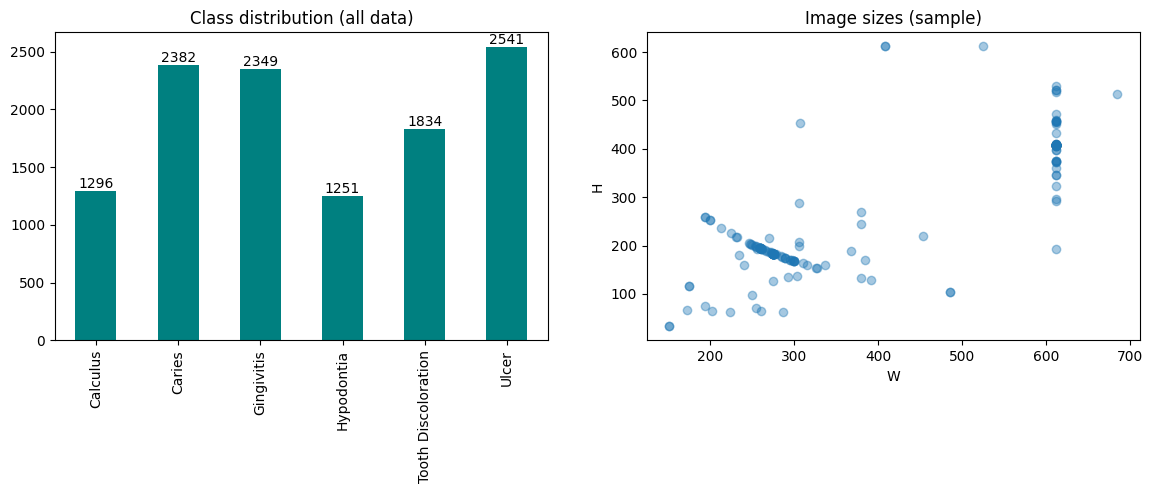

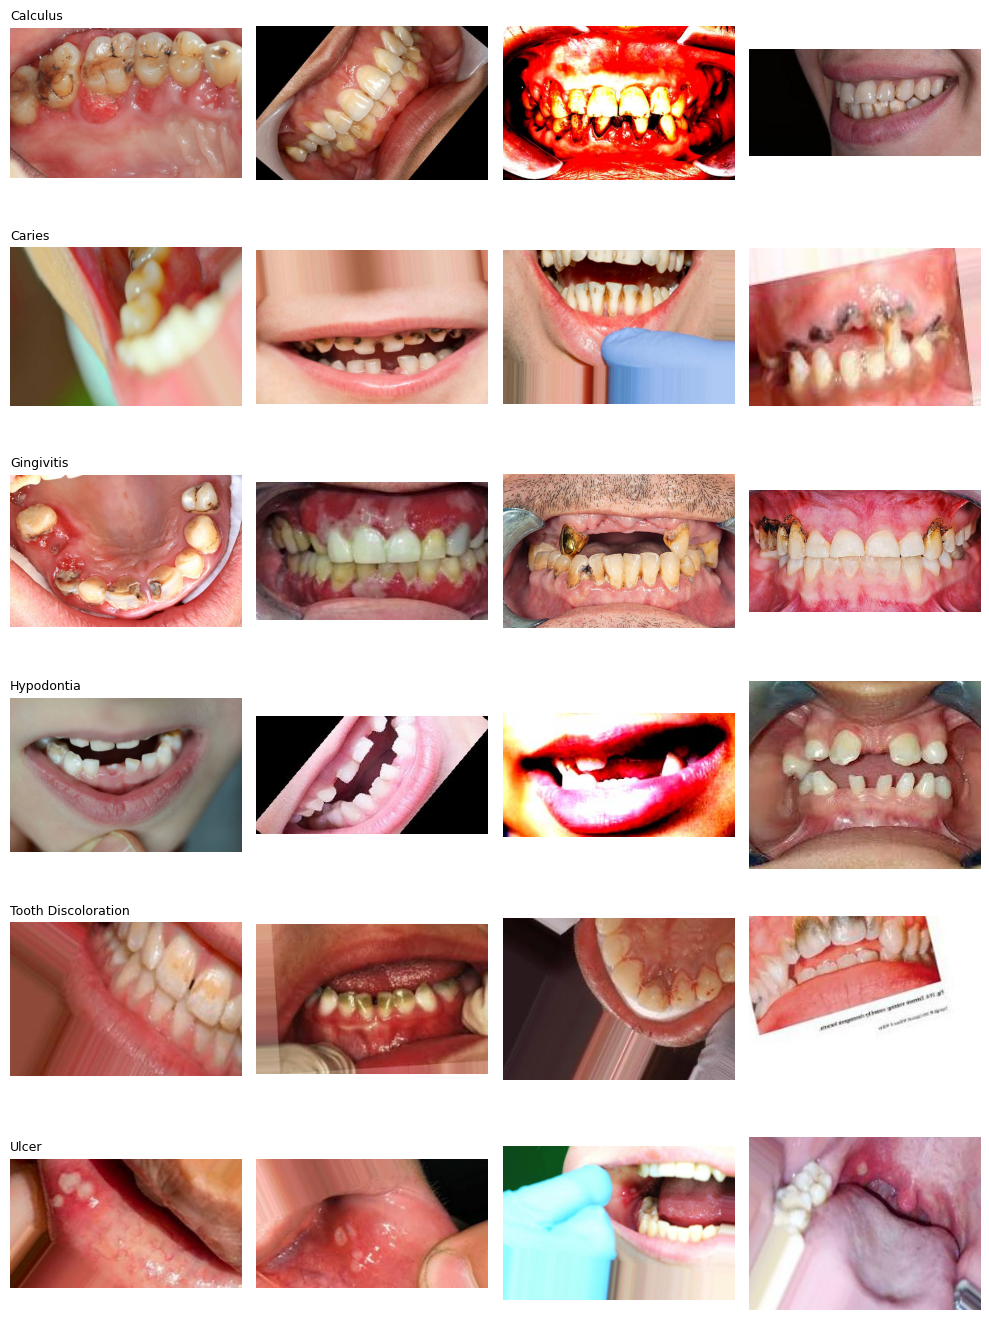

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14,4))
counts = pd.Series(Counter(targets)).sort_index(); counts.index = CLASSES
counts.plot.bar(ax=ax[0], color="teal"); ax[0].set_title("Class distribution (all data)")
for i,c in enumerate(counts): ax[0].text(i, c, str(c), ha="center", va="bottom")
sizes = [Image.open(full_train.samples[i][0]).size for i in np.random.choice(len(full_train), min(200,len(full_train)), replace=False)]
ax[1].scatter(*zip(*sizes), alpha=.4); ax[1].set_title("Image sizes (sample)"); ax[1].set_xlabel("W"); ax[1].set_ylabel("H")
plt.show()

fig, axes = plt.subplots(N_CLASSES, 4, figsize=(10, 2.3*N_CLASSES))
for r, c in enumerate(range(N_CLASSES)):
    paths = [p for p,l in full_train.samples if l == c][:4]
    for k, p in enumerate(paths):
        axes[r][k].imshow(Image.open(p).convert("RGB")); axes[r][k].axis("off")
        if k == 0: axes[r][k].set_title(CLASSES[c], fontsize=9, loc="left")
plt.tight_layout(); plt.show()

In [14]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); crit = nn.CrossEntropyLoss(weight=CLASS_W)
    P, L, tot = [], [], 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out = model(x)
        tot += crit(out.float(), y).item() * len(y)
        P.append(out.argmax(1).cpu()); L.append(y.cpu())
    P, L = torch.cat(P).numpy(), torch.cat(L).numpy()
    return dict(loss=tot/len(L), acc=accuracy_score(L,P), f1=f1_score(L,P,average="macro"), preds=P, labels=L)

def train_model(model, loaders, epochs, lr, wd=1e-4, opt_name="adamw", ls=0.0, patience=6, verbose=True):
    train_loader, val_loader = loaders[0], loaders[1]
    model.to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = {"adamw": lambda: optim.AdamW(params, lr=lr, weight_decay=wd),
           "adam":  lambda: optim.Adam(params, lr=lr, weight_decay=wd),
           "sgd":   lambda: optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)}[opt_name]()
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=CLASS_W, label_smoothing=ls)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist, best, best_state, bad = defaultdict(list), -1, None, 0
    for ep in range(epochs):
        model.train(); tl, tc, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                out = model(x); loss = crit(out.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item()*len(y); tc += (out.argmax(1)==y).sum().item(); n += len(y)
        sched.step()
        v = evaluate(model, val_loader)
        for k, val in [("train_loss",tl/n),("train_acc",tc/n),("val_loss",v["loss"]),("val_acc",v["acc"]),("val_f1",v["f1"])]:
            hist[k].append(val)
        if verbose:
            print(f"ep {ep+1:02d}/{epochs} | train {tl/n:.3f}/{tc/n:.3f} | val {v['loss']:.3f}/{v['acc']:.3f} f1 {v['f1']:.3f}")
        if v["acc"] > best:
            best, bad, best_state = v["acc"], 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: print("early stop"); break
    model.load_state_dict(best_state)
    return dict(hist)

def count_params(m): return sum(p.numel() for p in m.parameters())

In [15]:
class CustomCNN(nn.Module):
    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        def block(i, o): return nn.Sequential(
            nn.Conv2d(i,o,3,padding=1,bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
            nn.Conv2d(o,o,3,padding=1,bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
            nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3,32), block(32,64), block(64,128), block(128,256), block(256,256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(256,256), nn.ReLU(True), nn.Dropout(dropout), nn.Linear(256,n_classes))
    def forward(self, x): return self.head(self.features(x))

print(f"Custom CNN params: {count_params(CustomCNN(N_CLASSES))/1e6:.2f}M")

Custom CNN params: 2.42M


In [16]:
PRETRAINED = ["resnet50", "efficientnet_b0", "densenet121"]

def build_model(arch, n_classes, dropout=0.3, pretrained=True):
    if arch == "custom": return CustomCNN(n_classes, dropout)
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, n_classes))
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier[1].in_features, n_classes))
    elif arch == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier.in_features, n_classes))
    return m

def head_of(m, arch): return m.fc if arch == "resnet50" else m.classifier

def set_backbone(m, arch, trainable):
    for p in m.parameters(): p.requires_grad = trainable
    for p in head_of(m, arch).parameters(): p.requires_grad = True

def fit_pretrained(arch, loaders, lr=1e-4, wd=1e-4, opt_name="adamw", dropout=0.3, ls=0.0,
                   ep_head=3, ep_ft=12, verbose=True):
    """Stage 1: train the new head only. Stage 2: fine-tune the whole network at a lower LR."""
    m = build_model(arch, N_CLASSES, dropout).to(DEVICE)
    set_backbone(m, arch, False)
    h1 = train_model(m, loaders, ep_head, lr=1e-3, wd=wd, opt_name=opt_name, ls=ls, verbose=verbose)
    set_backbone(m, arch, True)
    h2 = train_model(m, loaders, ep_ft, lr=lr, wd=wd, opt_name=opt_name, ls=ls, verbose=verbose)
    return m, {k: h1[k] + h2[k] for k in h1}

In [17]:
import time, copy, random, os, json
from collections import defaultdict, Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import optuna

In [18]:
results, histories, ARCH = {}, {}, {}   # ARCH: display name -> (arch, dropout)

def register(name, arch, dropout, model, hist, train_time):
    te = evaluate(model, loaders[2]); va = evaluate(model, loaders[1])
    model.eval(); t0 = time.time()
    with torch.no_grad():
        for x, _ in loaders[2]: model(x.to(DEVICE))
    if USE_AMP: torch.cuda.synchronize()
    ms = (time.time()-t0)/len(te_idx)*1000
    results[name] = dict(val_acc=va["acc"], test_acc=te["acc"], test_f1=te["f1"], params_M=count_params(model)/1e6,
                         train_min=train_time/60, ms_per_img=ms, preds=te["preds"], labels=te["labels"])
    histories[name] = hist; ARCH[name] = (arch, dropout)
    torch.save(dict(arch=arch, dropout=dropout, state_dict={k:v.cpu() for k,v in model.state_dict().items()}, classes=CLASSES),
               f"{SAVE_DIR}/{name.replace(' ','_')}.pt")
    print(f"✔ {name}: val_acc={va['acc']:.4f} test_acc={te['acc']:.4f} test_f1={te['f1']:.4f}")

# ---- Custom CNN
t0 = time.time(); cnn = CustomCNN(N_CLASSES).to(DEVICE)
h = train_model(cnn, loaders, epochs=30, lr=1e-3, wd=1e-4, patience=8)
register("Custom CNN", "custom", 0.4, cnn, h, time.time()-t0)

ep 01/30 | train 1.507/0.366 | val 1.818/0.316 f1 0.293
ep 02/30 | train 1.220/0.497 | val 1.085/0.528 f1 0.498
ep 03/30 | train 1.148/0.519 | val 1.035/0.581 f1 0.538
ep 04/30 | train 1.085/0.557 | val 0.932/0.599 f1 0.578
ep 05/30 | train 1.023/0.585 | val 1.125/0.534 f1 0.493
ep 06/30 | train 0.975/0.606 | val 0.837/0.626 f1 0.611
ep 07/30 | train 0.937/0.629 | val 0.794/0.670 f1 0.646
ep 08/30 | train 0.880/0.642 | val 1.020/0.648 f1 0.610
ep 09/30 | train 0.843/0.664 | val 0.911/0.627 f1 0.590
ep 10/30 | train 0.791/0.683 | val 0.670/0.723 f1 0.706
ep 11/30 | train 0.758/0.702 | val 0.679/0.735 f1 0.710
ep 12/30 | train 0.716/0.715 | val 0.661/0.725 f1 0.701
ep 13/30 | train 0.699/0.726 | val 0.568/0.780 f1 0.761
ep 14/30 | train 0.637/0.745 | val 0.594/0.767 f1 0.741
ep 15/30 | train 0.622/0.756 | val 0.491/0.807 f1 0.789
ep 16/30 | train 0.603/0.772 | val 0.515/0.824 f1 0.805
ep 17/30 | train 0.577/0.782 | val 0.559/0.756 f1 0.736
ep 18/30 | train 0.528/0.791 | val 0.562/0.827 f

In [19]:
for arch in PRETRAINED:
    print(f"\n===== {arch} =====")
    set_seed(); t0 = time.time()
    m, h = fit_pretrained(arch, loaders, lr=1e-4, ep_head=3, ep_ft=12)
    register(arch, arch, 0.3, m, h, time.time()-t0)
    del m; torch.cuda.empty_cache()


===== resnet50 =====
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 180MB/s]


ep 01/3 | train 1.187/0.638 | val 0.861/0.766 f1 0.725
ep 02/3 | train 0.844/0.739 | val 0.719/0.794 f1 0.766
ep 03/3 | train 0.752/0.770 | val 0.691/0.787 f1 0.763
ep 01/12 | train 0.411/0.859 | val 0.190/0.937 f1 0.918
ep 02/12 | train 0.160/0.946 | val 0.126/0.962 f1 0.950
ep 03/12 | train 0.101/0.968 | val 0.074/0.982 f1 0.969
ep 04/12 | train 0.065/0.976 | val 0.098/0.959 f1 0.942
ep 05/12 | train 0.051/0.984 | val 0.048/0.985 f1 0.974
ep 06/12 | train 0.049/0.985 | val 0.030/0.990 f1 0.985
ep 07/12 | train 0.032/0.991 | val 0.031/0.989 f1 0.983
ep 08/12 | train 0.020/0.994 | val 0.028/0.991 f1 0.985
ep 09/12 | train 0.016/0.994 | val 0.032/0.989 f1 0.979
ep 10/12 | train 0.015/0.995 | val 0.030/0.991 f1 0.983
ep 11/12 | train 0.012/0.996 | val 0.029/0.991 f1 0.984
ep 12/12 | train 0.013/0.996 | val 0.028/0.991 f1 0.984
✔ resnet50: val_acc=0.9914 test_acc=0.9954 test_f1=0.9931

===== efficientnet_b0 =====
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-

100%|██████████| 20.5M/20.5M [00:00<00:00, 149MB/s]


ep 01/3 | train 1.142/0.625 | val 0.789/0.769 f1 0.736
ep 02/3 | train 0.837/0.715 | val 0.684/0.789 f1 0.758
ep 03/3 | train 0.761/0.737 | val 0.656/0.806 f1 0.777
ep 01/12 | train 0.486/0.825 | val 0.232/0.931 f1 0.914
ep 02/12 | train 0.232/0.920 | val 0.123/0.969 f1 0.955
ep 03/12 | train 0.145/0.952 | val 0.080/0.979 f1 0.970
ep 04/12 | train 0.101/0.970 | val 0.075/0.977 f1 0.964
ep 05/12 | train 0.077/0.975 | val 0.068/0.983 f1 0.975
ep 06/12 | train 0.054/0.984 | val 0.057/0.987 f1 0.980
ep 07/12 | train 0.049/0.984 | val 0.050/0.988 f1 0.981
ep 08/12 | train 0.045/0.986 | val 0.053/0.989 f1 0.980
ep 09/12 | train 0.039/0.987 | val 0.060/0.993 f1 0.985
ep 10/12 | train 0.042/0.989 | val 0.044/0.993 f1 0.985
ep 11/12 | train 0.036/0.989 | val 0.046/0.993 f1 0.986
ep 12/12 | train 0.029/0.991 | val 0.049/0.992 f1 0.984
✔ efficientnet_b0: val_acc=0.9934 test_acc=0.9927 test_f1=0.9932

===== densenet121 =====
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pt

100%|██████████| 30.8M/30.8M [00:00<00:00, 167MB/s]


ep 01/3 | train 1.268/0.539 | val 0.977/0.638 f1 0.610
ep 02/3 | train 0.948/0.665 | val 0.795/0.725 f1 0.700
ep 03/3 | train 0.880/0.682 | val 0.780/0.731 f1 0.702
ep 01/12 | train 0.473/0.832 | val 0.173/0.947 f1 0.930
ep 02/12 | train 0.206/0.934 | val 0.177/0.930 f1 0.895
ep 03/12 | train 0.146/0.950 | val 0.064/0.986 f1 0.979
ep 04/12 | train 0.098/0.969 | val 0.038/0.991 f1 0.985
ep 05/12 | train 0.060/0.982 | val 0.053/0.985 f1 0.973
ep 06/12 | train 0.044/0.988 | val 0.066/0.976 f1 0.963
ep 07/12 | train 0.037/0.988 | val 0.033/0.990 f1 0.983
ep 08/12 | train 0.033/0.990 | val 0.035/0.990 f1 0.982
ep 09/12 | train 0.032/0.991 | val 0.028/0.995 f1 0.991
ep 10/12 | train 0.026/0.993 | val 0.029/0.991 f1 0.983
ep 11/12 | train 0.019/0.995 | val 0.027/0.992 f1 0.985
ep 12/12 | train 0.019/0.995 | val 0.028/0.992 f1 0.985
✔ densenet121: val_acc=0.9947 test_acc=0.9940 test_f1=0.9929


In [20]:
base = {k: v for k, v in results.items() if k in PRETRAINED}
BEST_ARCH = max(base, key=lambda k: base[k]["val_acc"])
print("Tuning:", BEST_ARCH)

def objective(trial):
    p = dict(lr=trial.suggest_float("lr", 1e-5, 5e-4, log=True),
             wd=trial.suggest_float("wd", 1e-6, 1e-2, log=True),
             bs=trial.suggest_categorical("batch_size", [16, 32, 64]),
             dropout=trial.suggest_float("dropout", 0.1, 0.6),
             opt=trial.suggest_categorical("optimizer", ["adamw", "adam", "sgd"]),
             ls=trial.suggest_float("label_smoothing", 0.0, 0.15))
    set_seed(); ld = get_loaders(p["bs"])
    m, h = fit_pretrained(BEST_ARCH, ld, lr=p["lr"], wd=p["wd"], opt_name=p["opt"], dropout=p["dropout"],
                          ls=p["ls"], ep_head=2, ep_ft=4, verbose=False)
    acc = max(h["val_acc"]); del m; torch.cuda.empty_cache()
    return acc

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=12)   # raise to 20+ if you have time
print("Best val acc:", study.best_value); print("Best params:", study.best_params)
study.trials_dataframe()[["number","value","params_lr","params_wd","params_batch_size","params_dropout","params_optimizer","params_label_smoothing"]].sort_values("value", ascending=False)

[I 2026-10-26 21:09:03,812] A new study created in memory with name: no-name-11516e00-3418-4a5e-ae3d-4d9d70958228


Tuning: densenet121


[I 2026-10-26 21:16:22,581] Trial 0 finished with value: 0.9854014598540146 and parameters: {'lr': 4.3284502212938785e-05, 'wd': 0.006351221010640704, 'batch_size': 16, 'dropout': 0.17799726016810133, 'optimizer': 'adam', 'label_smoothing': 0.10621088666940683}. Best is trial 0 with value: 0.9854014598540146.
[I 2026-10-26 21:23:31,521] Trial 1 finished with value: 0.9077637690776377 and parameters: {'lr': 1.0838581269344744e-05, 'wd': 0.00757947995334801, 'batch_size': 16, 'dropout': 0.19170225492671691, 'optimizer': 'adam', 'label_smoothing': 0.043684371029706286}. Best is trial 0 with value: 0.9854014598540146.
[I 2026-10-26 21:29:30,836] Trial 2 finished with value: 0.7730590577305906 and parameters: {'lr': 0.00010952662748632558, 'wd': 3.6138942712165278e-06, 'batch_size': 64, 'dropout': 0.4925879806965068, 'optimizer': 'sgd', 'label_smoothing': 0.006967561907999659}. Best is trial 0 with value: 0.9854014598540146.
[I 2026-10-26 21:35:35,503] Trial 3 finished with value: 0.7604512

Best val acc: 0.9920371599203716
Best params: {'lr': 0.00020512599422151375, 'wd': 6.235377135673162e-06, 'batch_size': 32, 'dropout': 0.46450358402049363, 'optimizer': 'adamw', 'label_smoothing': 0.017380358928769456}


,number,value,params_lr,params_wd,params_batch_size,params_dropout,params_optimizer,params_label_smoothing
11,11,0.992037,0.000344,0.000010,32,0.105866,adamw,0.055877
7,7,0.992037,0.000205,0.000006,32,0.464504,adamw,0.017380
10,10,0.990710,0.000253,0.000010,32,0.104023,adamw,0.069755
0,0,0.985401,0.000043,0.006351,16,0.177997,adam,0.106211
5,5,0.982747,0.000444,0.001260,16,0.560937,adam,0.048800
6,6,0.971466,0.000046,0.000012,16,0.371348,adam,0.148033
8,8,0.933643,0.000293,0.000311,16,0.262592,sgd,0.070832
1,1,0.907764,0.000011,0.007579,16,0.191702,adam,0.043684
9,9,0.877903,0.000016,0.000713,64,0.346898,adamw,0.016184
2,2,0.773059,0.000110,0.000004,64,0.492588,sgd,0.006968


In [21]:
bp = study.best_params
set_seed(); loaders = get_loaders(bp["batch_size"]); t0 = time.time()
tuned, h = fit_pretrained(BEST_ARCH, loaders, lr=bp["lr"], wd=bp["wd"], opt_name=bp["optimizer"],
                          dropout=bp["dropout"], ls=bp["label_smoothing"], ep_head=3, ep_ft=15)
register(f"{BEST_ARCH} (tuned)", BEST_ARCH, bp["dropout"], tuned, h, time.time()-t0)

ep 01/3 | train 1.385/0.480 | val 1.013/0.639 f1 0.606
ep 02/3 | train 1.110/0.607 | val 0.848/0.717 f1 0.690
ep 03/3 | train 1.046/0.634 | val 0.837/0.716 f1 0.686
ep 01/15 | train 0.624/0.817 | val 0.204/0.940 f1 0.926
ep 02/15 | train 0.395/0.918 | val 0.213/0.915 f1 0.876
ep 03/15 | train 0.317/0.945 | val 0.076/0.981 f1 0.978
ep 04/15 | train 0.260/0.963 | val 0.060/0.983 f1 0.973
ep 05/15 | train 0.232/0.973 | val 0.063/0.985 f1 0.976
ep 06/15 | train 0.217/0.980 | val 0.068/0.985 f1 0.970
ep 07/15 | train 0.204/0.984 | val 0.055/0.989 f1 0.982
ep 08/15 | train 0.189/0.991 | val 0.039/0.993 f1 0.987
ep 09/15 | train 0.178/0.993 | val 0.048/0.993 f1 0.987
ep 10/15 | train 0.181/0.991 | val 0.036/0.993 f1 0.988
ep 11/15 | train 0.169/0.995 | val 0.042/0.991 f1 0.983
ep 12/15 | train 0.166/0.995 | val 0.037/0.994 f1 0.988
ep 13/15 | train 0.164/0.996 | val 0.036/0.994 f1 0.988
ep 14/15 | train 0.161/0.997 | val 0.035/0.994 f1 0.988
ep 15/15 | train 0.160/0.997 | val 0.034/0.994 f1 0

,Val Acc,Test Acc,Test Macro-F1,Params (M),Train (min),Inference (ms/img)
efficientnet_b0,0.9934,0.9927,0.9932,4.0152,13.9631,3.2563
resnet50,0.9914,0.9954,0.9931,23.5203,14.4847,3.7012
densenet121,0.9947,0.9940,0.9929,6.9600,15.4372,3.8660
densenet121 (tuned),0.9940,0.9954,0.9912,6.9600,19.5983,3.9010
Custom CNN,0.8812,0.9052,0.8971,2.4212,28.3418,3.4850


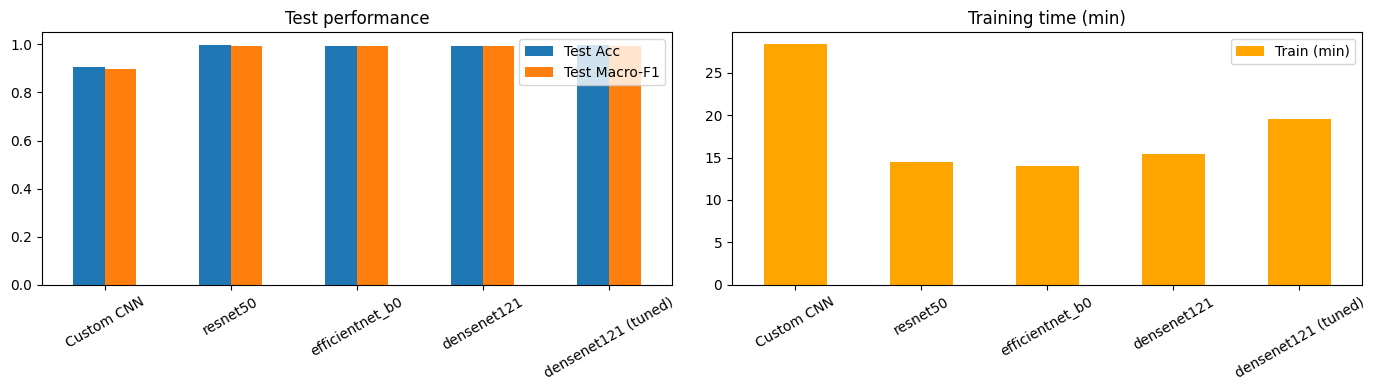

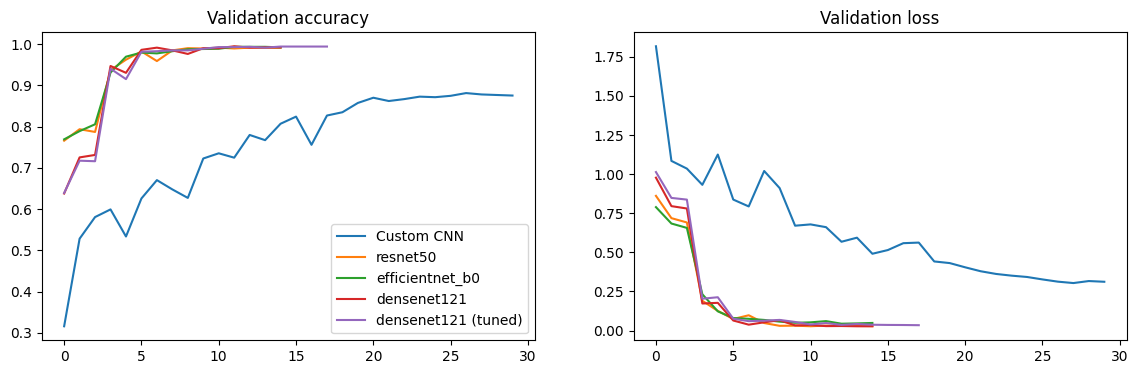

In [22]:
df = pd.DataFrame(results).T.drop(columns=["preds","labels"]).astype(float)
df = df.rename(columns={"val_acc":"Val Acc","test_acc":"Test Acc","test_f1":"Test Macro-F1","params_M":"Params (M)",
                        "train_min":"Train (min)","ms_per_img":"Inference (ms/img)"}).round(4)
display(df.sort_values("Test Macro-F1", ascending=False))
df.to_csv(f"{SAVE_DIR}/comparison.csv")

fig, ax = plt.subplots(1, 2, figsize=(14,4))
df[["Test Acc","Test Macro-F1"]].plot.bar(ax=ax[0]); ax[0].set_ylim(0, 1.05); ax[0].set_title("Test performance"); ax[0].tick_params(axis="x", rotation=30)
df[["Train (min)"]].plot.bar(ax=ax[1], color="orange"); ax[1].set_title("Training time (min)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

# Learning curves
fig, ax = plt.subplots(1, 2, figsize=(14,4))
for n, h in histories.items():
    ax[0].plot(h["val_acc"], label=n); ax[1].plot(h["val_loss"], label=n)
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss"); ax[0].legend(); plt.show()

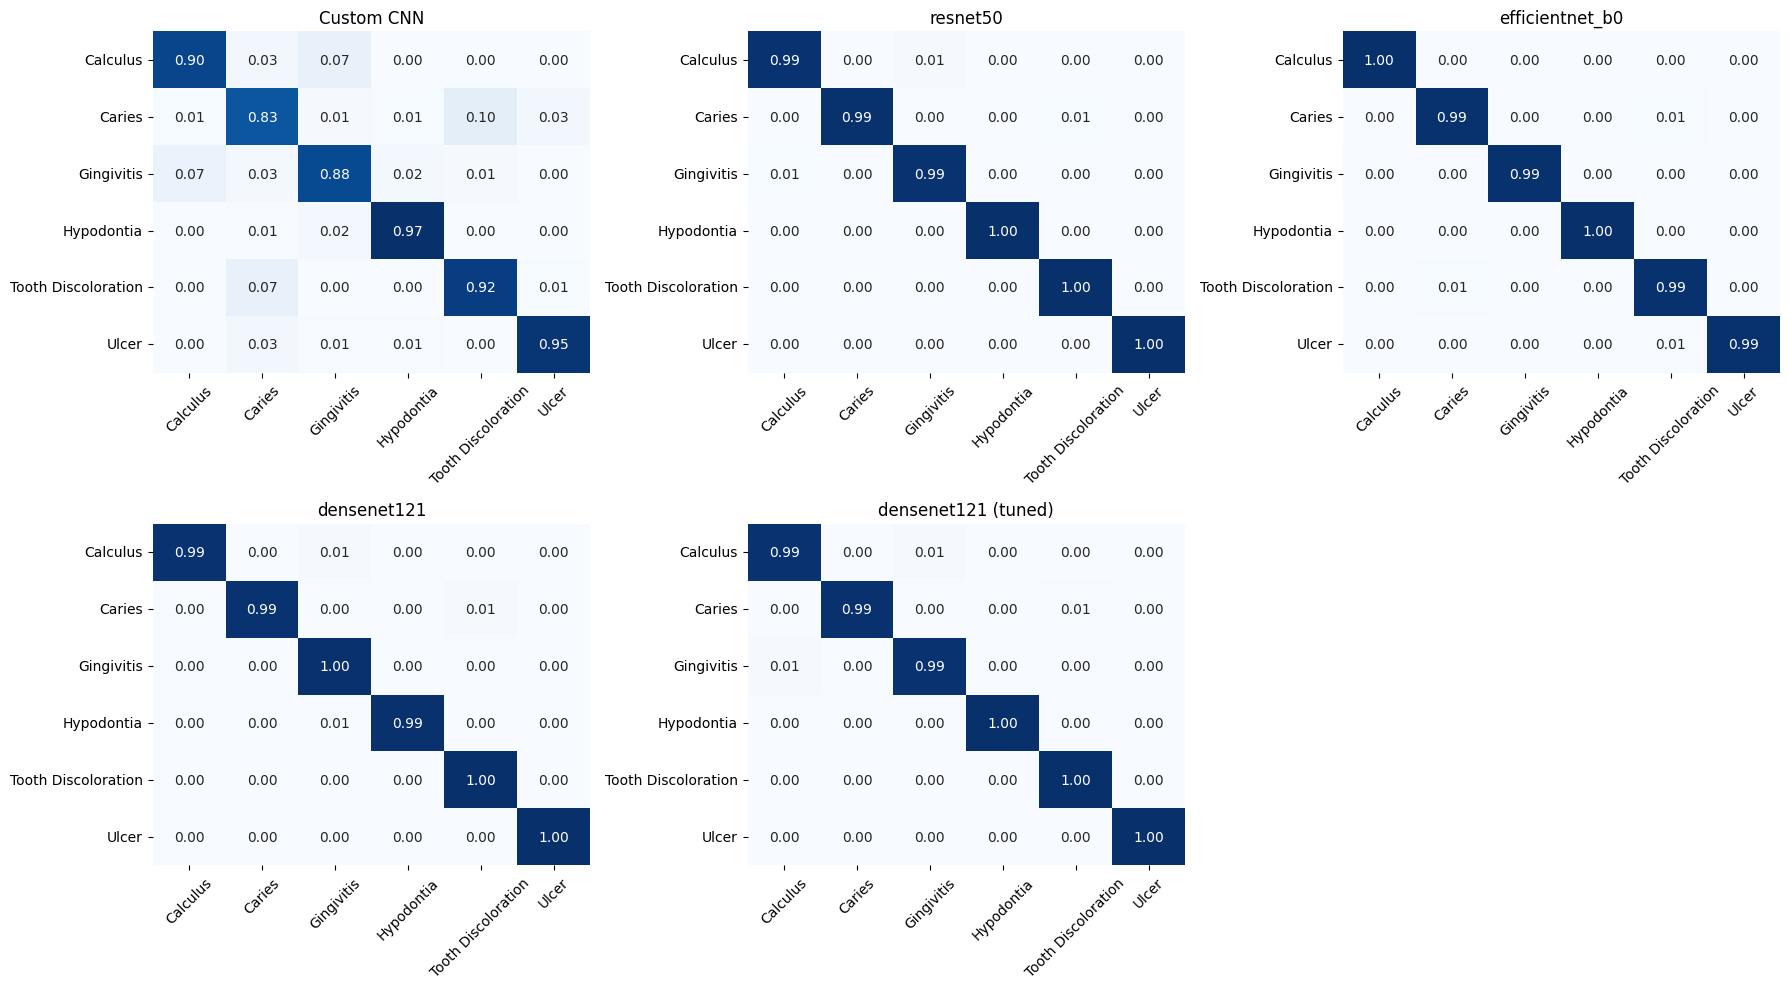

Selected model (highest validation accuracy): densenet121
                     precision    recall  f1-score   support

           Calculus      0.985     0.985     0.985        68
             Caries      0.997     0.986     0.992       358
         Gingivitis      0.992     0.996     0.994       240
         Hypodontia      1.000     0.995     0.997       186
Tooth Discoloration      0.982     0.996     0.989       275
              Ulcer      1.000     1.000     1.000       381

           accuracy                          0.994      1508
          macro avg      0.993     0.993     0.993      1508
       weighted avg      0.994     0.994     0.994      1508



In [23]:
n = len(results); cols = 3; rows = (n + cols - 1)//cols
fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows)); axes = np.array(axes).reshape(-1)
for a, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(r["labels"], r["preds"], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set_title(name); a.tick_params(axis="x", rotation=45)
for a in axes[n:]: a.axis("off")
plt.tight_layout(); plt.show()

WINNER = df["Val Acc"].idxmax()   # selected on validation, not test
print("Selected model (highest validation accuracy):", WINNER)
print(classification_report(results[WINNER]["labels"], results[WINNER]["preds"], target_names=CLASSES, digits=3))

In [24]:
import optuna.visualization as vis
vis.plot_param_importances(study).show()

In [25]:
ckpt = torch.load(f"{SAVE_DIR}/{WINNER.replace(' ','_')}.pt", map_location="cpu")
deploy = build_model(ckpt["arch"], len(ckpt["classes"]), ckpt["dropout"], pretrained=False)
deploy.load_state_dict(ckpt["state_dict"]); deploy.eval().to(DEVICE)
APP_CLASSES = ckpt["classes"]
print("Deploying:", WINNER, "| classes:", APP_CLASSES)

Deploying: densenet121 | classes: ['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Tooth Discoloration', 'Ulcer']


In [27]:
import gradio as gr

@torch.no_grad()
def predict(img):
    if img is None: return None
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(DEVICE)
    probs = torch.softmax(deploy(x), dim=1)[0].cpu().numpy()
    return {c: float(p) for c, p in zip(APP_CLASSES, probs)}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Upload an oral image"),
    outputs=gr.Label(num_top_classes=6, label="Prediction"),
    title="🦷 Oral Disease Classifier",
    description="For educational purposes only — not a medical diagnosis.",
    flagging_mode="never",
)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://148edda440854a3094.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
